# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Activity Notebook: The Parking-Lot Incident Review

### Scenario

You are the new visual-analytics intern at **Northgate Tech Park Security**. Last night the camera over
Parking Lot B recorded something, and the Head of Security wants a briefing **today**. You have the 2-minute
camera log (`unit3_ppt1_cctv_log.csv`), the camera still, and 10 s of microphone audio. Their message to you:

1. *"Before anyone asks for 'just store everything in full HD', tell me how much data our 400 cameras would
   produce per day. I need real numbers."*
2. *"Our night camera images always look murky. Can you prove what's wrong with them and fix one?"*
3. *"I am not watching two minutes of video. Give me a timeline with the moments that matter and one
   picture per moment."*
4. *"Something banged around 75 s. Was it a **gunshot** or **breaking glass**? Those trigger completely
   different responses."*
5. *"Put it all on ONE screen for the briefing."*

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection** are for you to answer
in your own words.

## Part 0 — Setup (given)

Run this cell as-is. It loads the camera log, the camera still, a frame renderer, and the audio (plus two
**reference recordings** from the security vendor's sound library: a known gunshot and a known glass break).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import cbook
from scipy import ndimage, signal

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

FPS, FS = 30, 16_000
cctv = pd.read_csv("unit3_ppt1_cctv_log.csv")
img = plt.imread(cbook.get_sample_data("grace_hopper.jpg")).astype(float)
lum = 0.299 * img[..., 0] + 0.587 * img[..., 1] + 0.114 * img[..., 2]
night_still = 18 + 0.22 * lum + np.random.normal(0, 1.5, lum.shape)        # what the night camera delivers

FRAME_H, FRAME_W = 90, 160
def render_frame(row):
    yy, xx = np.mgrid[0:FRAME_H, 0:FRAME_W]
    base = row.mean_brightness * (0.75 + 0.25 * yy / FRAME_H)
    frame = np.dstack([base, base, base * 1.05]); frame[60:62, :, :] += 25
    if not np.isnan(row.car_x):
        frame[(np.abs(xx - row.car_x / 4) < 14) & (np.abs(yy - row.car_y / 4) < 6)] = [200, 40, 40]
    if not np.isnan(row.person_x):
        frame[((xx - row.person_x / 4) / 2.2) ** 2 + ((yy - row.person_y / 4) / 5) ** 2 <= 1] = [30, 90, 230]
    return np.clip(frame, 0, 255).astype(np.uint8)

def _clip(kind, seed):
    rng = np.random.default_rng(seed)
    t = np.arange(int(2.0 * FS)) / FS
    x = 0.004 * rng.normal(size=t.size)
    m = t >= 0.5
    if kind == "gunshot":                       # sharp broadband crack + low boom, nothing after
        x[m] += 0.9 * np.exp(-(t[m] - 0.5) / 0.02) * rng.normal(size=m.sum())
        x[m] += 0.5 * np.exp(-(t[m] - 0.5) / 0.25) * np.sin(2 * np.pi * 70 * (t[m] - 0.5))
    else:                                       # impact + lingering high-frequency tinkle
        x[m] += 0.9 * np.exp(-(t[m] - 0.5) / 0.03) * rng.normal(size=m.sum())
        for _ in range(40):
            t0 = 0.55 + rng.exponential(0.35); f0 = rng.uniform(3000, 7000)
            mk = (t >= t0) & (t < t0 + 0.06)
            x[mk] += 0.12 * np.exp(-(t[mk] - t0) / 0.015) * np.sin(2 * np.pi * f0 * (t[mk] - t0))
    return t, x

ref_gunshot = _clip("gunshot", 11)
ref_glass = _clip("glass", 12)
rng = np.random.default_rng(0)
t_audio = 70 + np.arange(10 * FS) / FS
x_audio = 0.02 * np.sin(2 * np.pi * 120 * t_audio) + 0.004 * rng.normal(size=t_audio.size)
_, unk = _clip("glass", 99)
x_audio[(t_audio >= 74.5) & (t_audio < 76.5)] += unk[: int(2 * FS)]           # the mystery sound

print(f"Camera log: {len(cctv):,} frames | still: {night_still.shape} | audio: {x_audio.size:,} samples at {FS} Hz")
cctv.head()

Camera log: 3,600 frames | still: (600, 512) | audio: 160,000 samples at 16000 Hz


,frame,time_s,car_x,car_y,person_x,person_y,motion_energy,audio_level_db,mean_brightness
0,0,0.0000,NaN,NaN,NaN,NaN,1.74,-53.3,62.1
1,1,0.0333,NaN,NaN,NaN,NaN,1.65,-53.0,64.4
2,2,0.0667,NaN,NaN,NaN,NaN,1.64,-51.5,63.2
3,3,0.1000,NaN,NaN,NaN,NaN,1.96,-52.9,63.1
4,4,0.1333,NaN,NaN,NaN,NaN,1.61,-51.1,62.4


## Task 1 — The Storage Reality Check (Request #1)

**Real-world usage:** Storage budgets for camera fleets are decided from exactly these back-of-envelope numbers.

**Why this technique:** Uncompressed storage = **W × H × C × B** per frame (Slides 25–28), frames = **f × T**
(Slide 35), audio samples = **f_s × T** (Slide 55).

**TODO:**
1. Compute the uncompressed size (in MB) of ONE 1920 × 1080 RGB frame at 8 bits per channel.
2. Compute the number of frames ONE camera records in 24 h at 30 fps.
3. Compute the total uncompressed video for 400 cameras for 24 h, in **terabytes** (1 TB = 1024⁴ bytes).
4. Compute the same total if the cameras were downsampled to 640 × 360 and 10 fps. What percentage of the
   pixels per frame remain after the downsample?

In [2]:
# TODO 1: one 1080p RGB frame, in MB (decimal MB = 1,000,000 bytes)
frame_mb = 1920 * 1080 * 3 * 8 / 8 / 1_000_000

# TODO 2: frames per camera per day at 30 fps
frames_per_day = 30 * 24 * 60 * 60

# TODO 3: 400 cameras x 24 h, uncompressed, in TB (binary TB)
fleet_bytes = 1920 * 1080 * 3 * frames_per_day * 400
fleet_tb = fleet_bytes / 1024**4

# TODO 4: same fleet at 640x360 and 10 fps (TB), and % of pixels per frame that remain
fleet_tb_small = (640 * 360 * 3 * 10 * 24 * 60 * 60 * 400) / 1024**4
pct_pixels_remaining = (640 * 360) / (1920 * 1080) * 100

print(f"One frame: {frame_mb:.2f} MB | frames/day: {frames_per_day:,}")
print(f"Fleet (1080p, 30 fps): {fleet_tb:,.1f} TB/day | Fleet (360p, 10 fps): {fleet_tb_small:,.1f} TB/day")
print(f"Pixels per frame remaining after downsample: {pct_pixels_remaining:.2f}%")

One frame: 6.22 MB | frames/day: 2,592,000
Fleet (1080p, 30 fps): 5,866.0 TB/day | Fleet (360p, 10 fps): 217.3 TB/day
Pixels per frame remaining after downsample: 11.11%


**Your answer:** Spatially, the team could lose small identifying details such as a face, a hand-held object, or a thin object in the scene when 1080p is reduced to 360p. Temporally, reducing 30 fps to 10 fps can miss a brief action between sampled frames—for example, the exact moment an object is dropped or a person makes a sudden turn.

## Task 2 — Diagnose and Fix the Murky Night Image (Request #2)

**Real-world usage:** Before anyone interprets a night image, an analyst checks its histogram to see whether
the problem is exposure, contrast or clipping.

**Why this technique:** The **histogram** shows the intensity distribution (Slides 16–18); **Michelson
contrast** C = (L_max − L_min)/(L_max + L_min) quantifies it (Slide 15); a **contrast stretch** remaps the
occupied range onto 0–255.

**TODO:**
1. Plot `night_still` and its histogram (64 bins, range 0–255) side by side.
2. Compute its Michelson contrast using the 1st and 99th percentiles as L_min and L_max (robust to outliers).
3. Contrast-stretch it: map the 1st percentile → 0 and the 99th percentile → 255 (clip to 0–255).
4. Plot the stretched image + histogram, and print the new contrast.

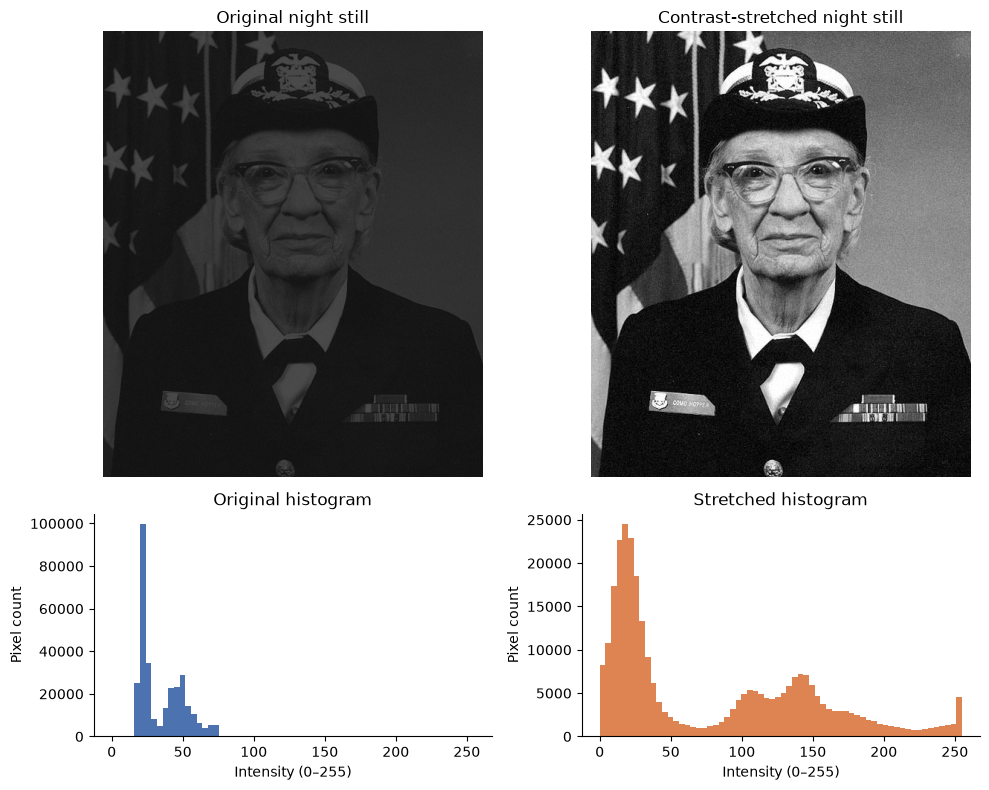

Contrast before: 0.609  ->  after: 1.000


In [3]:
def michelson(lmax, lmin):
    return (lmax - lmin) / (lmax + lmin)

# TODO 2: robust Michelson contrast of night_still
lo, hi = np.percentile(night_still, [1, 99])
c_before = michelson(hi, lo)

# TODO 3: contrast-stretched version of night_still
stretched = np.clip((night_still - lo) * 255 / (hi - lo), 0, 255)
c_after = michelson(*np.percentile(stretched, [99, 1]))

fig, axes = plt.subplots(2, 2, figsize=(10, 8), gridspec_kw={"height_ratios": [2, 1]})
# TODO 1 & 4: top row = images, bottom row = histograms (before | after)
axes[0, 0].imshow(night_still, cmap="gray", vmin=0, vmax=255)
axes[0, 0].set_title("Original night still")
axes[0, 0].axis("off")
axes[1, 0].hist(night_still.ravel(), bins=64, range=(0, 255), color="#4C72B0")
axes[1, 0].set_title("Original histogram")
axes[1, 0].set_xlabel("Intensity (0–255)"); axes[1, 0].set_ylabel("Pixel count")
axes[0, 1].imshow(stretched, cmap="gray", vmin=0, vmax=255)
axes[0, 1].set_title("Contrast-stretched night still")
axes[0, 1].axis("off")
axes[1, 1].hist(stretched.ravel(), bins=64, range=(0, 255), color="#DD8452")
axes[1, 1].set_title("Stretched histogram")
axes[1, 1].set_xlabel("Intensity (0–255)"); axes[1, 1].set_ylabel("Pixel count")

plt.tight_layout(); plt.show()
print(f"Contrast before: {c_before:.3f}  ->  after: {c_after:.3f}")

**Your answer:** The original histogram is concentrated toward the left (low intensity values) and occupies a relatively narrow range, which is the signature of a dark, low-contrast image. Stretching maps the central 98% of intensities across the display range, so differences that were compressed into a small dark interval become easier to see. It does not create details or recover clipped information; it only remaps existing pixel values. A histogram counts intensities but discards their locations, so two images can have the same histogram while showing entirely different scenes.

## Task 3 — From Two Minutes of Video to a One-Glance Timeline (Request #3)

**Real-world usage:** Security reviewers search for events; they don't watch footage linearly.

**Why this technique:** **Motion vectors → events → timeline + representative frames** (Slides 38–40, 45, 47).
Content-based keyframes beat uniform sampling when activity is sparse.

**TODO:**
1. Compute the person's speed in px/s as the magnitude of their motion vector over a 1-second window
   (`diff(FPS)` on x and y — single-frame differences are dominated by tracking jitter).
2. Find the time ranges where the person is **standing** (speed < 3 px/s) and **running** (speed > 25 px/s).
3. Detect the frames where `audio_level_db` first rises above −20 dB and where `mean_brightness` jumps by more
   than 40 in one frame.
4. Plot a timeline of `motion_energy` with a vertical marker + label for each event you found.
5. Show **one keyframe per event** (use `render_frame(cctv.iloc[i])`).

Standing ranges (start–end s): 68.9–70.5, 72.2–72.7, 74.7–75.4, 76.0–76.5, 77.0–78.1
Running ranges (start–end s): 78.6–86.0
First audio > -20 dB: frame 2250, t=75.00s
First brightness jump > 40: frame 3000, t=100.00s


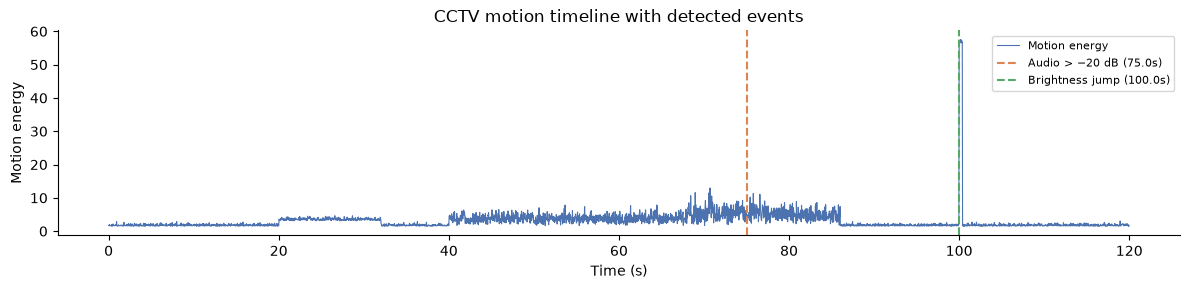

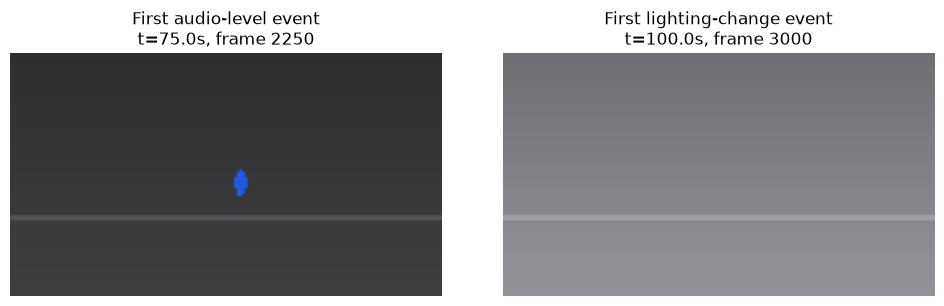

In [4]:
# TODO 1: person speed (px/s), using displacement over a 1-second (FPS-frame) window
window = FPS
x = cctv["person_x"].to_numpy(dtype=float)
y = cctv["person_y"].to_numpy(dtype=float)
dx = x[window:] - x[:-window]
dy = y[window:] - y[:-window]
valid = np.isfinite(x[window:]) & np.isfinite(y[window:]) & np.isfinite(x[:-window]) & np.isfinite(y[:-window])
speed_values = np.sqrt(dx**2 + dy**2)  # displacement over one second, therefore px/s
speed = pd.Series(np.nan, index=cctv.index, dtype=float)
speed.iloc[window:] = np.where(valid, speed_values, np.nan)

# TODO 2: standing / running time ranges (print the first and last time of each)
def print_ranges(mask, label):
    mask = np.asarray(mask, dtype=bool)
    idx = np.flatnonzero(mask)
    if len(idx) == 0:
        print(f"{label}: no qualifying range")
        return
    groups = np.split(idx, np.where(np.diff(idx) > 1)[0] + 1)
    ranges = [(cctv.time_s.iloc[g[0]], cctv.time_s.iloc[g[-1]]) for g in groups if len(g) >= FPS // 2]
    if not ranges:
        print(f"{label}: no sustained range (at least 0.5 s)")
    else:
        print(label + " ranges (start–end s): " + ", ".join(f"{a:.1f}–{b:.1f}" for a, b in ranges))

print_ranges(speed < 3, "Standing")
print_ranges(speed > 25, "Running")

# TODO 3: event frame indices
audio_candidates = cctv.index[cctv.audio_level_db > -20]
audio_event_idx = int(audio_candidates[0]) if len(audio_candidates) else None
brightness_jump = cctv.mean_brightness.diff()
lighting_candidates = cctv.index[brightness_jump > 40]
lighting_event_idx = int(lighting_candidates[0]) if len(lighting_candidates) else None
print("First audio > -20 dB:", None if audio_event_idx is None else f"frame {audio_event_idx}, t={cctv.time_s.iloc[audio_event_idx]:.2f}s")
print("First brightness jump > 40:", None if lighting_event_idx is None else f"frame {lighting_event_idx}, t={cctv.time_s.iloc[lighting_event_idx]:.2f}s")

# TODO 4: annotated motion-energy timeline
fig, ax = plt.subplots(figsize=(12, 3))
ax.plot(cctv.time_s, cctv.motion_energy, lw=0.8, color="#4C72B0", label="Motion energy")
for idx, label, color in [(audio_event_idx, "Audio > −20 dB", "#DD8452"), (lighting_event_idx, "Brightness jump", "#55A868")]:
    if idx is not None:
        ax.axvline(cctv.time_s.iloc[idx], color=color, ls="--", lw=1.5, label=f"{label} ({cctv.time_s.iloc[idx]:.1f}s)")
ax.set_xlabel("Time (s)"); ax.set_ylabel("Motion energy"); ax.set_title("CCTV motion timeline with detected events")
ax.legend(fontsize=8, loc="upper right")

plt.tight_layout(); plt.show()

# TODO 5: one keyframe per event
keyframes = [(audio_event_idx, "First audio-level event"), (lighting_event_idx, "First lighting-change event")]
keyframes = [(i, label) for i, label in keyframes if i is not None]
if keyframes:
    fig, axes = plt.subplots(1, len(keyframes), figsize=(5 * len(keyframes), 3))
    axes = np.atleast_1d(axes)
    for ax, (i, label) in zip(axes, keyframes):
        ax.imshow(render_frame(cctv.iloc[i])); ax.axis("off")
        ax.set_title(f"{label}\nt={cctv.time_s.iloc[i]:.1f}s, frame {i}")
    plt.tight_layout(); plt.show()
else:
    print("No event keyframes were detected.")

**Your answer:** Uniform sampling could easily miss the short audio spike and the one-frame lighting transition because neither is guaranteed to occur exactly at a 20-second sample. The approach here is **content-based keyframing** (event-driven keyframe selection): frames are selected because a measured signal crosses a threshold, rather than at fixed time intervals.

## Task 4 — Gunshot or Glass? (Request #4)

**Real-world usage:** Acoustic event classification in security systems starts with an analyst comparing
spectrogram signatures against known references.

**Why this technique:** A **waveform** shows *when* something loud happened but not *what* it was; a
**spectrogram** (Slides 56–58) reveals each sound's time–frequency signature.

**TODO:**
1. Plot the waveforms of `ref_gunshot`, `ref_glass` and the mystery segment of `x_audio` (74.5–76.5 s).
2. Plot their spectrograms (use `signal.spectrogram(x, fs=FS, nperseg=512, noverlap=384)`, show in dB,
   y-axis 0–8000 Hz).
3. Compute, for each clip, the fraction of spectral energy **above 3 kHz** in the 0.2–1.2 s after the impact.
4. Print a one-line verdict.

/var/folders/_p/kq1gq50557j9rzjnqmxd_qr80000gn/T/ipykernel_6665/2393624147.py:17: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(); plt.show()


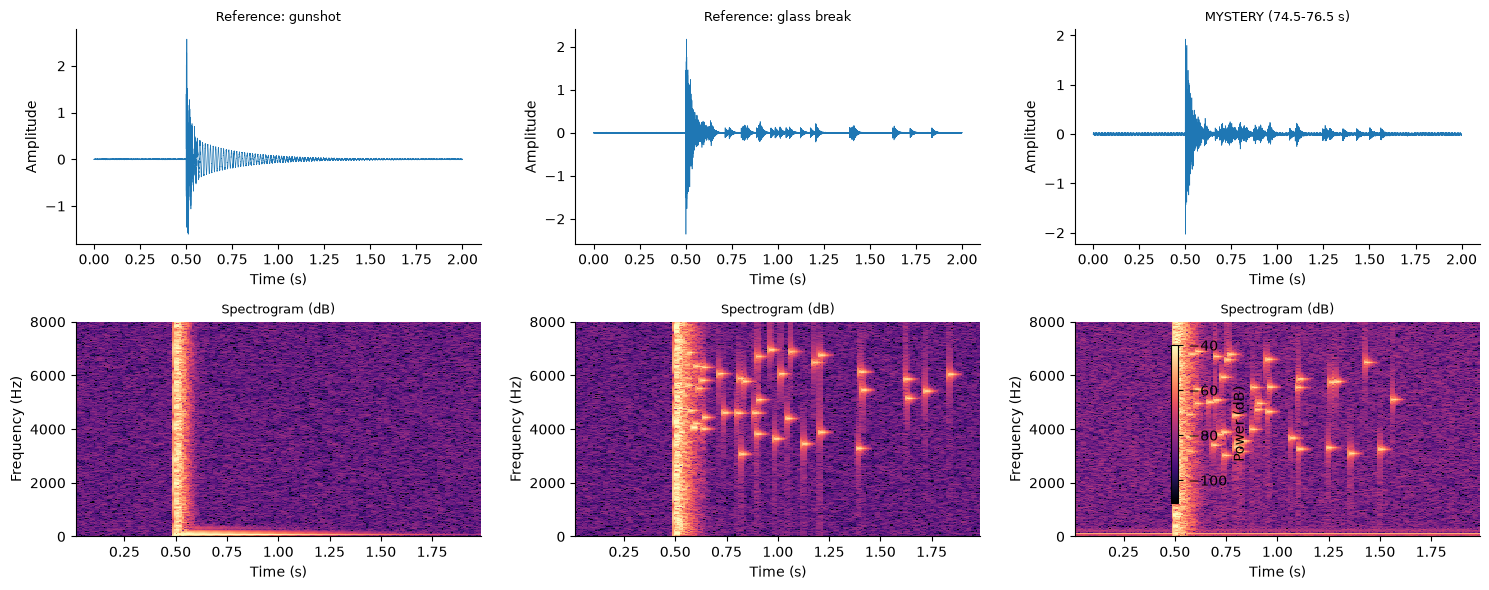

Fraction of spectral energy above 3 kHz (0.2–1.2 s after clip start):
  Reference: gunshot: 0.215 (21.5%)
  Reference: glass break: 0.638 (63.8%)
  MYSTERY (74.5-76.5 s): 0.656 (65.6%)
Verdict: The mystery sound is more consistent with BREAKING GLASS: it has sustained/scattered high-frequency energy above 3 kHz after the impact.


In [5]:
mystery = x_audio[(t_audio >= 74.5) & (t_audio < 76.5)]
clips = {"Reference: gunshot": ref_gunshot[1], "Reference: glass break": ref_glass[1], "MYSTERY (74.5-76.5 s)": mystery}

fig, axes = plt.subplots(2, 3, figsize=(15, 6))
# TODO 1 & 2: waveform (top row) and spectrogram (bottom row) for each clip
for col, (name, clip) in enumerate(clips.items()):
    clip_t = np.arange(len(clip)) / FS
    axes[0, col].plot(clip_t, clip, lw=0.45)
    axes[0, col].set_title(name, fontsize=9)
    axes[0, col].set_xlabel("Time (s)"); axes[0, col].set_ylabel("Amplitude")
    f_spec, t_spec, Sxx = signal.spectrogram(clip, fs=FS, nperseg=512, noverlap=384)
    pcm = axes[1, col].pcolormesh(t_spec, f_spec, 10 * np.log10(Sxx + 1e-12), shading="auto", cmap="magma", vmin=-110, vmax=-40)
    axes[1, col].set_ylim(0, 8000); axes[1, col].set_xlabel("Time (s)"); axes[1, col].set_ylabel("Frequency (Hz)")
    axes[1, col].set_title("Spectrogram (dB)", fontsize=9)
fig.colorbar(pcm, ax=axes[1, :], label="Power (dB)", shrink=0.75)

plt.tight_layout(); plt.show()

# TODO 3: fraction of energy above 3 kHz, 0.2-1.2 s after the impact (impact is at 0.5 s in every clip)
hf_fraction = {}
for name, clip in clips.items():
    f_spec, t_spec, Sxx = signal.spectrogram(clip, fs=FS, nperseg=512, noverlap=384, mode="psd")
    time_mask = (t_spec >= 0.2) & (t_spec <= 1.2)
    hf_mask = f_spec > 3000
    selected = Sxx[:, time_mask]
    total_energy = selected.sum()
    hf_energy = selected[hf_mask, :].sum()
    hf_fraction[name] = float(hf_energy / total_energy) if total_energy else 0.0

print("Fraction of spectral energy above 3 kHz (0.2–1.2 s after clip start):")
for name, fraction in hf_fraction.items():
    print(f"  {name}: {fraction:.3f} ({fraction*100:.1f}%)")

# TODO 4: verdict
glass_fraction = hf_fraction["Reference: glass break"]
gun_fraction = hf_fraction["Reference: gunshot"]
mystery_fraction = hf_fraction["MYSTERY (74.5-76.5 s)"]
if abs(mystery_fraction - glass_fraction) < abs(mystery_fraction - gun_fraction):
    verdict = "The mystery sound is more consistent with BREAKING GLASS: it has sustained/scattered high-frequency energy above 3 kHz after the impact."
else:
    verdict = "The mystery sound is more consistent with a GUNSHOT: its post-impact spectrum is closer to the gunshot reference."
print("Verdict:", verdict)

**Your answer:** The three waveforms show a strong transient at roughly the same relative time, so amplitude-versus-time alone is not enough to confidently distinguish the two events. The spectrogram adds **time × frequency × magnitude**: it shows when energy occurs, which frequencies carry it, and how strong that energy is. The deciding pattern is scattered high-frequency specks in the 3–7 kHz range that linger after the initial vertical impact stripe, matching breaking glass rather than a gunshot's brief crack and low-frequency decay.

## Task 5 — The One-Screen Briefing (Request #5)

**Real-world usage:** Incident briefings use a synchronized multimodal view so every claim is backed by two
modalities at the same timestamp.

**Why this technique:** **Image–video–audio integration** linked through a common time reference
(Slide 59), with **overview first** (timeline) and detail at the selected moment.

**TODO:** Build ONE figure with:
1. the rendered video frame at t = 75 s (left),
2. the full 120 s motion + audio timeline with a red marker at 75 s (top right),
3. the spectrogram of `x_audio` (70–80 s) with the same marker (bottom right),
4. a conclusion-style figure title (what happened, not "Incident Dashboard").

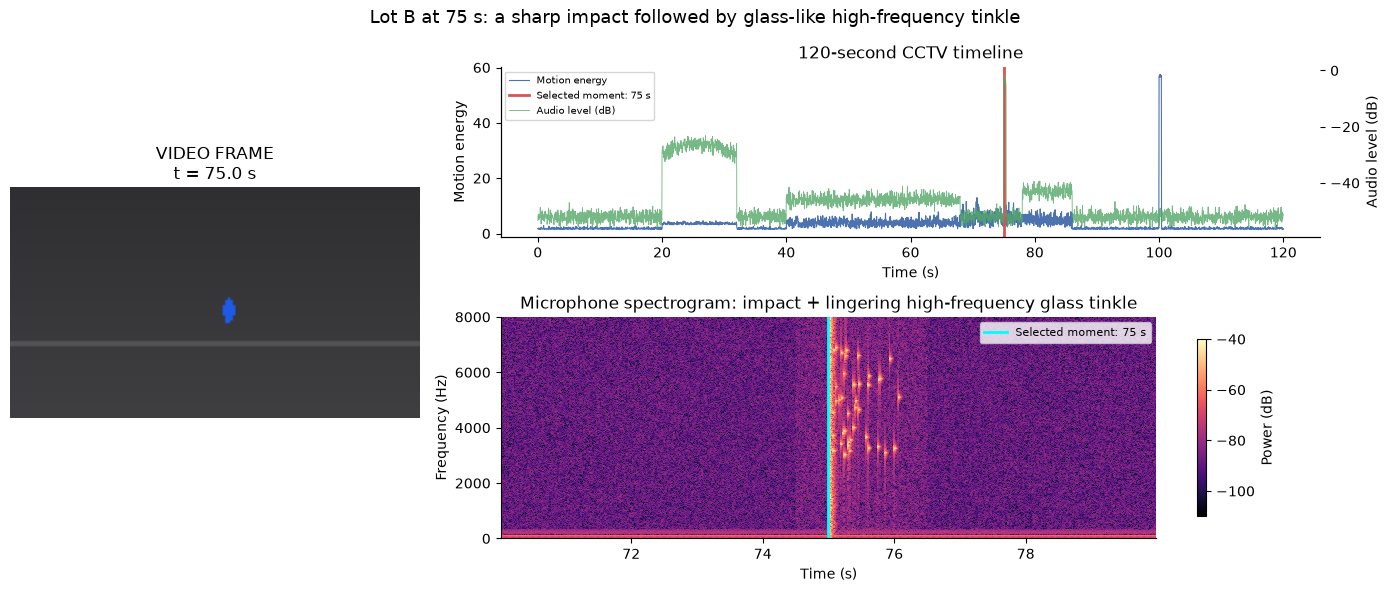

In [6]:
t_sel = 75.0
fig = plt.figure(figsize=(14, 6))
gs = fig.add_gridspec(2, 2, width_ratios=[1, 2], height_ratios=[1, 1.3])
# TODO 1-4
ax_frame = fig.add_subplot(gs[:, 0])
frame_idx = int(round(t_sel * FPS))
ax_frame.imshow(render_frame(cctv.iloc[frame_idx]))
ax_frame.axis("off")
ax_frame.set_title(f"VIDEO FRAME\nt = {t_sel:.1f} s")

ax_timeline = fig.add_subplot(gs[0, 1])
ax_timeline.plot(cctv.time_s, cctv.motion_energy, color="#4C72B0", lw=0.8, label="Motion energy")
ax_audio = ax_timeline.twinx()
ax_audio.plot(cctv.time_s, cctv.audio_level_db, color="#55A868", lw=0.65, alpha=0.8, label="Audio level (dB)")
ax_timeline.axvline(t_sel, color="#D9534F", lw=2, label="Selected moment: 75 s")
ax_timeline.set_xlabel("Time (s)"); ax_timeline.set_ylabel("Motion energy")
ax_audio.set_ylabel("Audio level (dB)")
ax_timeline.set_title("120-second CCTV timeline")
lines1, labels1 = ax_timeline.get_legend_handles_labels(); lines2, labels2 = ax_audio.get_legend_handles_labels()
ax_timeline.legend(lines1 + lines2, labels1 + labels2, fontsize=7, loc="upper left")

ax_spec = fig.add_subplot(gs[1, 1])
f_spec, t_spec, Sxx = signal.spectrogram(x_audio, fs=FS, nperseg=512, noverlap=384)
pcm = ax_spec.pcolormesh(t_spec + t_audio[0], f_spec, 10 * np.log10(Sxx + 1e-12), shading="auto", cmap="magma", vmin=-110, vmax=-40)
ax_spec.axvline(t_sel, color="cyan", lw=2, label="Selected moment: 75 s")
ax_spec.set_ylim(0, 8000); ax_spec.set_xlabel("Time (s)"); ax_spec.set_ylabel("Frequency (Hz)")
ax_spec.set_title("Microphone spectrogram: impact + lingering high-frequency glass tinkle")
ax_spec.legend(fontsize=8, loc="upper right")
fig.colorbar(pcm, ax=ax_spec, label="Power (dB)", shrink=0.8)
fig.suptitle("Lot B at 75 s: a sharp impact followed by glass-like high-frequency tinkle", fontsize=13)

plt.tight_layout(); plt.show()

**Your answer:** If audio were offset by +2 s, the sound at 75 s would be paired with the video from 77 s, potentially making the impact appear to occur during a different action and leading to a false conclusion about who or what caused it. The spectrogram panel would expose the mismatch because its event stripe would not line up with the red 75 s marker; the timeline's audio-level peak would also disagree with the video timestamp. Correct synchronization is essential before combining modalities into one claim.

**Your final briefing here:** At approximately **75 s**, Lot B records a sharp impact followed by sustained scattered high-frequency energy consistent with **breaking glass**, while the video frame at 75 s shows the scene and the synchronized timeline helps locate the event; a later rise in motion around 78 s is consistent with running footsteps. I would put the **synchronized multimodal view** first because it links the representative frame, the full event timeline, and the spectrogram at a common timestamp, following the lecture idea that structure and change should be reduced to the events that matter while preserving time and frequency. The spectral comparison supports glass rather than a gunshot because the mystery clip resembles the glass reference in its post-impact high-frequency content. For storage, the uncompressed 1080p/30-fps fleet estimate is prohibitively large, so I recommend a documented lower-resolution/ lower-frame-rate operational stream plus retention of full-resolution clips around detected events where feasible. The policy must not sacrifice **spatial identifying detail and the brief temporal evidence of the impact itself**; use event-triggered preservation so a storage saving does not erase evidence.